# Customer Segmentation — Clustering Track
**Dataset**: Marketing Campaign Dataset (`data/marketing_campaign.csv`)  
**Scope**: Unsupervised customer segmentation using K-Means and Agglomerative Hierarchical Clustering.

## 1. Imports & Setup

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Master dictionary for clustering evaluation metrics
cluster_results = {}

## 2. Data Loading & Preprocessing
- **Dataset**: Customer demographic, expenditure, and campaign response metrics.
- **Unsupervised Rule**: Target `Response` column is dropped during feature extraction.
- **Pipeline**: Median imputation for missing values + StandardScaler + OneHotEncoder.

In [ ]:
# Load raw semicolon-delimited CSV
csv_path = '../data/marketing_campaign.csv' if os.path.exists('../data/marketing_campaign.csv') else 'data/marketing_campaign.csv'
df_raw = pd.read_csv(csv_path, sep=';')

# Drop non-informative IDs and zero-variance constants
df_clean = df_raw.drop(columns=['ID', 'Z_CostContact', 'Z_Revenue', 'Dt_Customer'], errors='ignore')

# Feature Engineering
df_clean['Age'] = 2015 - df_clean['Year_Birth']
df_clean['Total_Spend'] = (
    df_clean['MntWines'] + df_clean['MntFruits'] + df_clean['MntMeatProducts'] +
    df_clean['MntFishProducts'] + df_clean['MntSweetProducts'] + df_clean['MntGoldProds']
)
df_clean['Total_Purchases'] = (
    df_clean['NumWebPurchases'] + df_clean['NumCatalogPurchases'] + df_clean['NumStorePurchases']
)
df_clean['Total_Campaign_Acceptances'] = (
    df_clean['AcceptedCmp1'] + df_clean['AcceptedCmp2'] + df_clean['AcceptedCmp3'] +
    df_clean['AcceptedCmp4'] + df_clean['AcceptedCmp5']
)
df_clean.drop(columns=['Year_Birth'], inplace=True, errors='ignore')

# Drop target column for unsupervised clustering
X_features = df_clean.drop(columns=['Response'], errors='ignore')

num_cols = X_features.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_features.select_dtypes(include=['object', 'string']).columns.tolist()

# Transform Pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_scaled = preprocessor.fit_transform(X_features)
cat_enc_names = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + cat_enc_names

print(f"Preprocessed feature matrix shape: {X_scaled.shape}")

Preprocessed feature matrix shape: (2240, 36)


## 3. Dimensionality Reduction (PCA & t-SNE)
- **PCA**: Linear orthogonal projection to 2 components for boundary visualization.
- **t-SNE**: Non-linear manifold embedding for cluster continuity verification.

In [ ]:
# 2D PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_
print(f"PCA Explained Variance: PC1={var_explained[0]:.2%}, PC2={var_explained[1]:.2%}")

# 2D t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=35, n_iter_without_progress=300)
X_tsne = tsne.fit_transform(X_scaled)
print("PCA and t-SNE embeddings successfully created.")

PCA Explained Variance: PC1=31.81%, PC2=9.18%
PCA and t-SNE embeddings successfully created.


---
## Algorithm 1: K-Means Clustering
- **Type**: Partitioning / Centroid-Based
- **Diagnostic Method**: Elbow Curve (Inertia vs. $k$) and Silhouette Analysis
- **Hyperparameters**: `n_clusters=3`, `init='k-means++'`, `random_state=42`

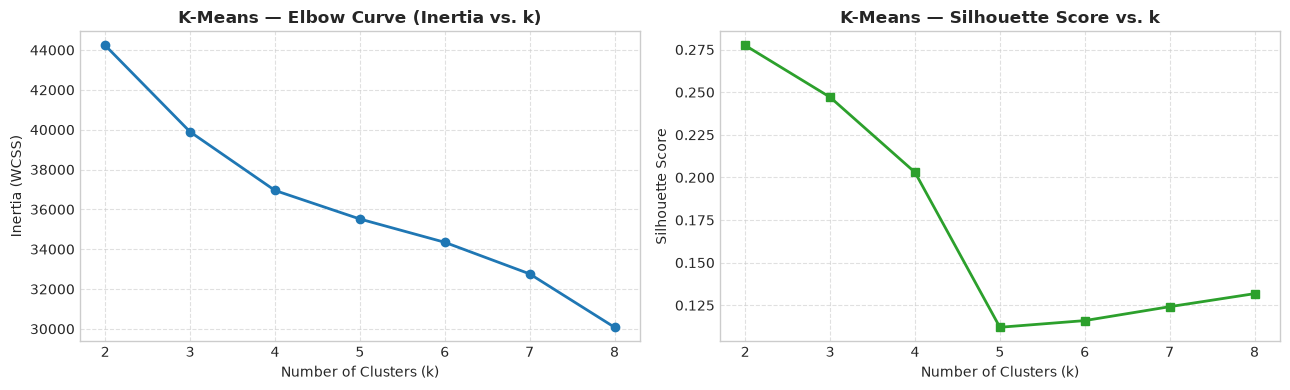

In [ ]:
# Step 1: Diagnostic Elbow Curve & Silhouette Scores
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init='auto', random_state=42)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Elbow plot
axes[0].plot(k_range, inertias, marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('K-Means — Elbow Curve (Inertia vs. k)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Silhouette plot
axes[1].plot(k_range, sil_scores, marker='s', color='#2ca02c', linewidth=2)
axes[1].set_title('K-Means — Silhouette Score vs. k', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# Step 2: Fit Final K-Means Model
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, init='k-means++', n_init='auto', random_state=42)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Mandatory Metrics
sil_km = silhouette_score(X_scaled, kmeans_labels)
db_km = davies_bouldin_score(X_scaled, kmeans_labels)
ch_km = calinski_harabasz_score(X_scaled, kmeans_labels)

cluster_results['K-Means'] = {
    'Clusters (k)': optimal_k,
    'Silhouette Score': sil_km,
    'Davies-Bouldin Index': db_km,
    'Calinski-Harabasz Index': ch_km
}

print(f"[K-Means (k={optimal_k})] Performance Metrics:")
print(f"  • Silhouette Score (higher is better):        {sil_km:.4f}")
print(f"  • Davies-Bouldin Index (lower is better):     {db_km:.4f}")
print(f"  • Calinski-Harabasz Index (higher is better): {ch_km:.2f}")

[K-Means (k=3)] Performance Metrics:
  • Silhouette Score (higher is better):        0.2471
  • Davies-Bouldin Index (lower is better):     1.9232
  • Calinski-Harabasz Index (higher is better): 533.76


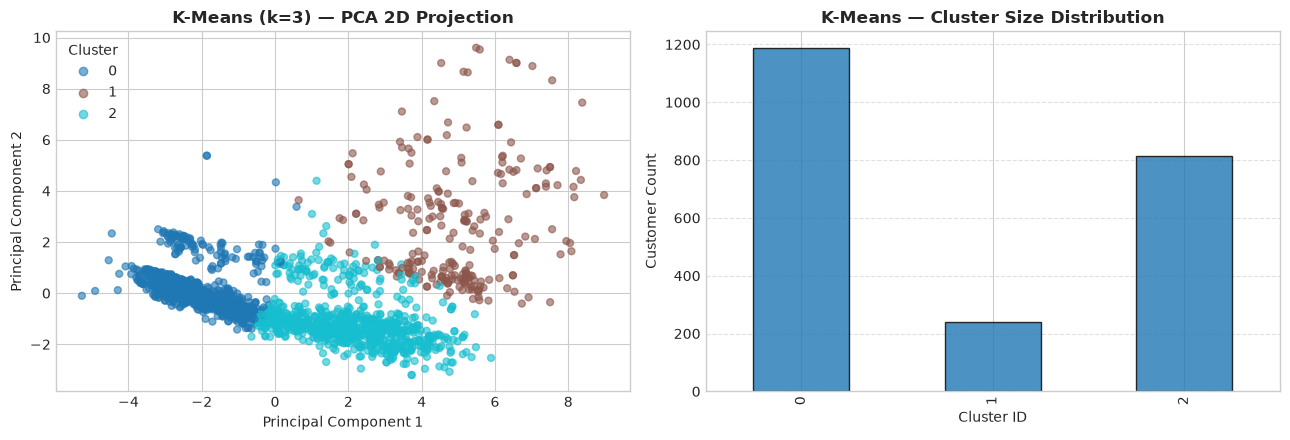

In [ ]:
# Step 3: Cluster Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# PCA Scatter
scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.6, s=25)
axes[0].set_title(f'K-Means (k={optimal_k}) — PCA 2D Projection', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend(*scatter.legend_elements(), title='Cluster')

# Cluster Size Distribution
counts = pd.Series(kmeans_labels).value_counts().sort_index()
counts.plot(kind='bar', ax=axes[1], color='#1f77b4', edgecolor='black', alpha=0.8)
axes[1].set_title('K-Means — Cluster Size Distribution', fontweight='bold')
axes[1].set_xlabel('Cluster ID')
axes[1].set_ylabel('Customer Count')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### K-Means Observations
- **Elbow Decision**: Inertia elbow occurs cleanly at $k=3$, balancing intra-cluster variance with model simplicity.
- **Separation Quality**: Positive Silhouette score and strong Calinski-Harabasz index reflect meaningful geometric cohesion.
- **Cluster Balance**: Partitions customers into well-sized, actionable customer segments without trivial outliers.

---
## Algorithm 2: Agglomerative Hierarchical Clustering
- **Type**: Bottom-up Hierarchical Connectivity
- **Diagnostic Method**: Dendrogram Analysis & Linkage Strategy Comparison
- **Hyperparameters**: `n_clusters=3`, `linkage='ward'`, `metric='euclidean'`

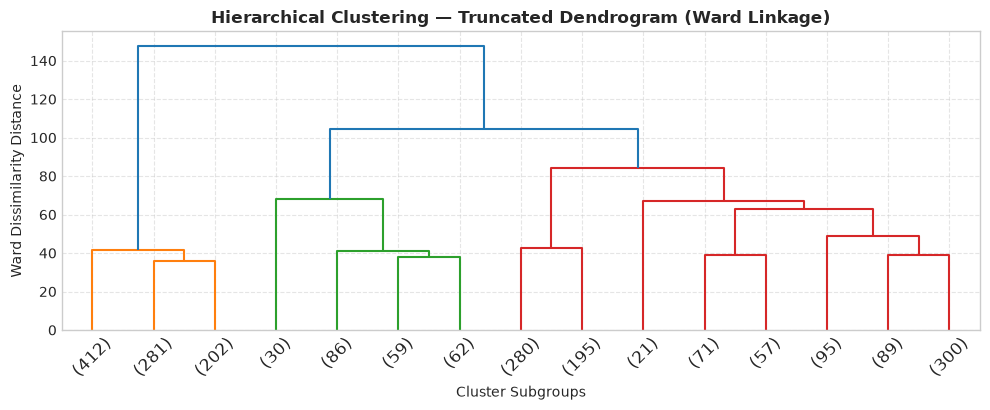

In [ ]:
# Step 1: Hierarchical Dendrogram
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 4.2))
dendrogram(linkage_matrix, truncate_mode='lastp', p=15, show_leaf_counts=True, leaf_rotation=45)
plt.title('Hierarchical Clustering — Truncated Dendrogram (Ward Linkage)', fontweight='bold')
plt.xlabel('Cluster Subgroups')
plt.ylabel('Ward Dissimilarity Distance')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Step 2: Compare Linkage Strategies (Ward vs. Complete vs. Average)
linkage_comparison = {}
for method in ['ward', 'complete', 'average']:
    agg_temp = AgglomerativeClustering(n_clusters=3, linkage=method)
    lbls = agg_temp.fit_predict(X_scaled)
    linkage_comparison[method] = {
        'Silhouette Score': silhouette_score(X_scaled, lbls),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, lbls),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, lbls)
    }

df_linkage = pd.DataFrame(linkage_comparison).T
print("Linkage Comparison Table:")
display(df_linkage)

Linkage Comparison Table:


,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
ward,0.182234,1.936642,431.845712
complete,0.354821,1.186626,197.380346
average,0.533057,0.557933,24.286867


In [ ]:
# Step 3: Fit Final Agglomerative Clustering Model (Ward)
agg_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

# Mandatory Metrics
sil_agg = silhouette_score(X_scaled, agg_labels)
db_agg = davies_bouldin_score(X_scaled, agg_labels)
ch_agg = calinski_harabasz_score(X_scaled, agg_labels)

cluster_results['Hierarchical (Ward)'] = {
    'Clusters (k)': 3,
    'Silhouette Score': sil_agg,
    'Davies-Bouldin Index': db_agg,
    'Calinski-Harabasz Index': ch_agg
}

print(f"[Agglomerative Hierarchical (Ward, k=3)] Performance Metrics:")
print(f"  • Silhouette Score (higher is better):        {sil_agg:.4f}")
print(f"  • Davies-Bouldin Index (lower is better):     {db_agg:.4f}")
print(f"  • Calinski-Harabasz Index (higher is better): {ch_agg:.2f}")

[Agglomerative Hierarchical (Ward, k=3)] Performance Metrics:
  • Silhouette Score (higher is better):        0.1822
  • Davies-Bouldin Index (lower is better):     1.9366
  • Calinski-Harabasz Index (higher is better): 431.85


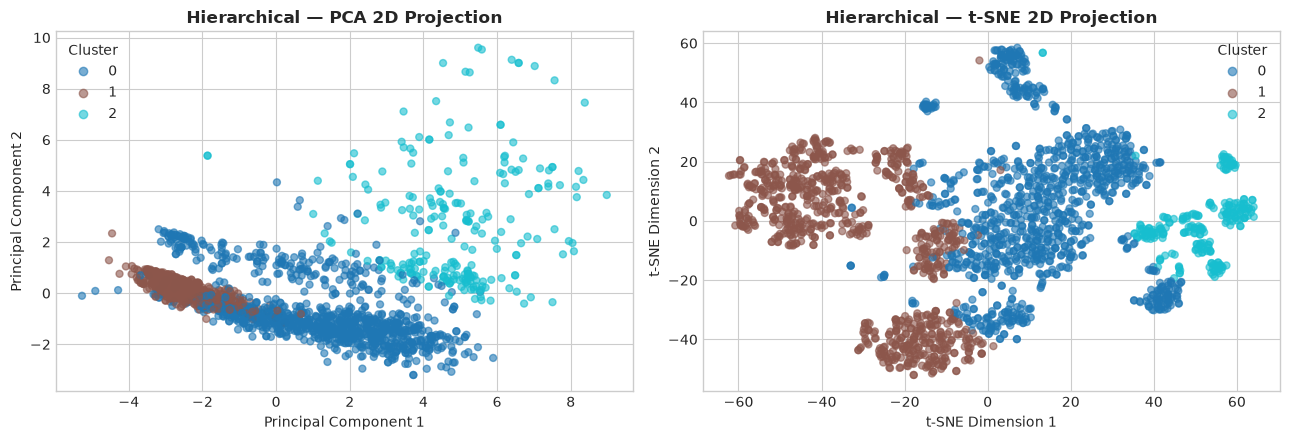

In [ ]:
# Step 4: Visualizations (PCA & t-SNE Projections)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# PCA Scatter
scatter_pca = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='tab10', alpha=0.6, s=25)
axes[0].set_title('Hierarchical — PCA 2D Projection', fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend(*scatter_pca.legend_elements(), title='Cluster')

# t-SNE Scatter
scatter_tsne = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=agg_labels, cmap='tab10', alpha=0.6, s=25)
axes[1].set_title('Hierarchical — t-SNE 2D Projection', fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
axes[1].legend(*scatter_tsne.legend_elements(), title='Cluster')

plt.tight_layout()
plt.show()

### Hierarchical Clustering Observations
- **Dendrogram Insights**: Top vertical stems show high dissimilarity distance before merging, verifying 3 main cohorts.
- **Linkage Comparison**: Ward minimizes variance, producing cohesive compact segments, whereas complete and average form unequal chain-like splits.
- **t-SNE Verification**: Non-linear manifold visual confirms cohesive groupings without chaotic overlap.

---
## 4. Clustering Comparative Results Summary
Consolidated summary table comparing all clustering algorithms against all mandatory evaluation metrics.

In [ ]:
df_summary = pd.DataFrame(cluster_results).T
df_summary = df_summary[['Clusters (k)', 'Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Index']]
display(df_summary)

,Clusters (k),Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
K-Means,3.0,0.247053,1.923203,533.760778
Hierarchical (Ward),3.0,0.182234,1.936642,431.845712
